# 01 · Exploring the sourced candidates

**Goal:** understand the data before building any ranking: what each column contains, how clean it is, and which candidates clearly don't belong on the list.

**The search:** "aspiring human resources" or "seeking human resources".

**Questions this notebook answers**
1. Do we have labels to learn from?
2. Are there duplicate candidates?
3. Should connections or location be part of the fit score?
4. Which candidates should not be on this list in the first place?

## 1. The raw file, exactly as delivered

In [1]:
import re
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd

from talent_ranker.config import DATA_PATH, FIGURES_DIR
from talent_ranker.data import deduplicate, load_candidates

pd.set_option("display.max_colwidth", 120)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

raw = pd.read_excel(DATA_PATH)
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 104 entries, 0 to 103
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   id          104 non-null    int64  
 1   job_title   104 non-null    str    
 2   location    104 non-null    str    
 3   connection  104 non-null    object 
 4   fit         0 non-null      float64
dtypes: float64(1), int64(1), object(1), str(2)
memory usage: 4.2+ KB


In [2]:
raw.isna().sum()

id              0
job_title       0
location        0
connection      0
fit           104
dtype: int64

**Finding: there are no labels.** `fit` is empty for all 104 candidates.

This shapes the whole project:
- We can't train a model to predict `fit`, because there are no examples to learn from.
- The first fit score has to come from how closely each job title matches the search keywords (text similarity).
- The recruiter's stars become the only feedback, and the ranking learns from them as they arrive.
- To *measure* whether a ranking is good, we need a small set of hand-made labels (Step 2).

Also, `connection` holds text such as `"500+"`, so it has to be converted to a number.

## 2. Cleaning and duplicates
`load_candidates()` does three things:
- checks the file (required columns, no empty cells, unique ids);
- cleans job titles (line breaks, `|` separators, extra spaces);
- turns connections into numbers.

`deduplicate()` then merges rows that share the same title, location **and** connections.

In [3]:
candidates = load_candidates()
profiles = deduplicate(candidates)
profiles["copies"] = profiles["ids"].map(len)
print(f"{len(candidates)} rows -> {len(profiles)} unique profiles")
print(profiles["copies"].value_counts().sort_index().to_dict())
profiles.sort_values("copies", ascending=False).head(8)[["job_title", "location", "copies"]]

104 rows -> 53 unique profiles
{1: 39, 2: 2, 4: 5, 5: 3, 6: 2, 7: 2}


,job_title,location,copies
0,2019 C.T. Bauer College of Business Graduate (Magna Cum Laude) and aspiring Human Resources professional,"Houston, Texas",7
6,Student at Humber College and Aspiring Human Resources Generalist,Kanada,7
2,Aspiring Human Resources Professional,"Raleigh-Durham, North Carolina Area",6
3,People Development Coordinator at Ryan,"Denton, Texas",6
1,Native English Teacher at EPIK (English Program in Korea),Kanada,5
7,HR Senior Specialist,San Francisco Bay Area,5
5,Aspiring Human Resources Specialist,Greater New York City Area,5
4,Advisory Board Member at Celal Bayar University,"İzmir, Türkiye",4


**Finding: the 104 rows are only 53 different people.** 39 people appear once, and 14 appear between 2 and 7 times. For example, the C.T. Bauer graduate in Houston and the Humber College student in Canada each appear 7 times.

Why this matters:
- Without deduplication, one person could take 7 of the top 10 places, and a reviewer would read the same profile 7 times.
- Every metric would count that person 7 times and distort the results.
- We keep the list of original `ids` for each profile. The client still gets a score for each of the 104 rows, and starring any copy stars them all.

From here on, the analysis uses the **53 unique profiles**.

## 3. Connections
The file caps connections at "500+". We store 500, the only honest lower bound, plus a `connections_capped` flag that records that the true value may be higher.

Share of profiles capped at 500+: 34%


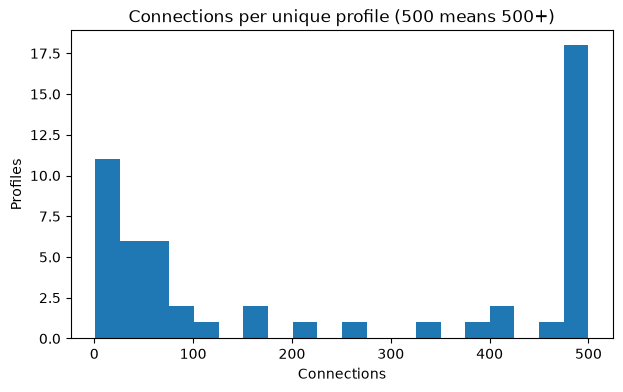

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(profiles["connections"], bins=20)
ax.set(
    title="Connections per unique profile (500 means 500+)",
    xlabel="Connections",
    ylabel="Profiles",
)
fig.savefig(FIGURES_DIR / "connections.png", dpi=150, bbox_inches="tight")
print(f"Share of profiles capped at 500+: {profiles['connections_capped'].mean():.0%}")

**Finding:** 34% of profiles are capped at 500+. That's the tall bar at 500: for a third of the candidates we don't know the real number. The others range from 1 to 455.

### Would connections help or hurt the fit score?
"Aspiring" candidates are early in their careers by definition. We compare their connections with everyone else's.

In [5]:
early_career = profiles["job_title"].str.contains("aspiring|seeking|student", case=False)
profiles.groupby(early_career)["connections"].median().rename(
    index={True: "aspiring / seeking / student", False: "everyone else"}
)

job_title
everyone else                   500.0
aspiring / seeking / student     62.5
Name: connections, dtype: float64

**Finding: the people we're searching for have far fewer connections.** Profiles that mention "aspiring", "seeking" or "student" have a median of **62.5** connections, against **500** for everyone else, about 8 times fewer.

Connections measure network size and time spent on LinkedIn, not talent or fit for a role. Adding them to the fit score would push down exactly the candidates this search is looking for.

**Decision: connections are not part of the fit score.** Step 3 tests this with numbers.

*Note: this word search is a rough grouping. For example, it also catches a staffing agency's job ad. The gap is large enough that it doesn't change the conclusion.*

## 4. Locations

In [6]:
profiles["location"].value_counts().head(10)

location
Houston, Texas Area                    4
Raleigh-Durham, North Carolina Area    3
Greater New York City Area             3
Kanada                                 2
Greater Philadelphia Area              2
Austin, Texas Area                     2
Amerika Birleşik Devletleri            2
Greater Atlanta Area                   2
Houston, Texas                         1
Denton, Texas                          1
Name: count, dtype: int64

**Finding: locations are inconsistent.** The same city appears in different forms ("Houston, Texas" and "Houston, Texas Area"), and some names are in Turkish ("Kanada" = Canada, "Amerika Birleşik Devletleri" = United States, "İzmir, Türkiye").

**Decision: location is not part of the fit score.** Where someone lives says nothing about their ability, and scoring on it would bring in geographic bias. If a client needs candidates in a specific place, location should be a separate filter that the recruiter switches on deliberately, not a hidden part of the score.

## 5. Reading every title
There are only 52 distinct titles, so we can read all of them. We do this **before** building any model, so our judgement doesn't depend on what a model later says.

In [7]:
for title in sorted(profiles["job_title"].unique()):
    print("-", title)

- 2019 C.T. Bauer College of Business Graduate (Magna Cum Laude) and aspiring Human Resources professional
- Admissions Representative at Community medical center long beach
- Advisory Board Member at Celal Bayar University
- Always set them up for Success
- Aspiring Human Resources Management student seeking an internship
- Aspiring Human Resources Manager Graduating May 2020 Seeking an Entry-Level Human Resources Position in St. Louis
- Aspiring Human Resources Manager, seeking internship in Human Resources.
- Aspiring Human Resources Professional
- Aspiring Human Resources Professional An energetic and Team-Focused Leader
- Aspiring Human Resources Professional Passionate about helping to create an inclusive and engaging work environment
- Aspiring Human Resources Specialist
- Bachelor of Science in Biology from Victoria University of Wellington
- Business Intelligence and Analytics at Travelers
- Business Management Major and Aspiring Human Resources Manager
- Director Human Resour

### Who belongs on an "aspiring / seeking human resources" list?

Grouping the 53 profiles by hand:

| Group | Profiles | Examples |
|---|---|---|
| **Aspiring or seeking HR** (the target) | 19 | "Aspiring Human Resources Professional", "Seeking Human Resources Position", "Student at Humber College and Aspiring Human Resources Generalist", "Retired Army National Guard Recruiter … seeking a position in Human Resources" |
| **Already working in HR** (right field, later career stage) | 16 | "Human Resources Generalist at Loparex", "HR Senior Specialist", "People Development Coordinator at Ryan", "Director Human Resources at EY" |
| **Not HR** | 13 | "Native English Teacher at EPIK", "Bachelor of Science in Biology …", "Junior MES Engineer", "RRP Brand Portfolio Executive at JTI", "Seeking employment opportunities within Customer Service or Patient Care" |
| **Too vague to judge** | 4 | "Student", "Student at Chapman University", "Student at Westfield State University", "Always set them up for Success" |
| **Not a candidate** | 1 | "Nortia Staffing is seeking Human Resources, Payroll & Administrative Professionals!! (408) 709-2621" |

### Candidates who should not be on this list, and why
- **Not a person:** the Nortia Staffing entry is a company's job ad with a phone number. It should be removed whatever the role.
- **Not HR:** the 13 profiles above have nothing in their title that points to human resources.
- **Wrong career stage:** "SVP, CHRO …", "Director Human Resources at EY" and "Director of Human Resources North America" work in HR but are far beyond "aspiring". They could suit a senior search, so they should be *flagged*, not deleted.
- **Too vague:** a bare "Student" may or may not be a future HR professional. These should be flagged for a person to check, not dropped. Losing a high-potential candidate costs more than spending a few seconds reviewing one.

### Traps for keyword matching (these matter in Steps 2–3)
- The **Nortia Staffing ad** contains the exact words "seeking Human Resources", so word matching will rank it near the top even though it isn't a candidate. A filter is needed (Step 5).
- **"Seeking employment opportunities within Customer Service or Patient Care"** contains "seeking" but has nothing to do with HR.
- **"People Development Coordinator"** is an HR role with no HR words, and **"HR Senior Specialist"** uses the abbreviation. Word matching will miss them; a model that compares meaning should not.

These groups become the labelling rules in Step 2.

## 6. Which words dominate the titles?

In [8]:
words = Counter(
    word for title in profiles["job_title"].str.lower() for word in re.findall(r"[a-z]+", title)
)
words.most_common(15)

[('human', 34),
 ('resources', 34),
 ('at', 22),
 ('and', 13),
 ('aspiring', 13),
 ('seeking', 10),
 ('professional', 9),
 ('manager', 7),
 ('in', 6),
 ('university', 6),
 ('student', 6),
 ('management', 6),
 ('of', 5),
 ('business', 5),
 ('generalist', 5)]

**Finding:** "human" and "resources" are the most common words (34 times each), and "aspiring" (13) and "seeking" (10) are also frequent. "at" (22) usually means "role at company", so that person is currently employed.

Many titles share the exact words of the search keywords, so simple word matching (Step 2) should already work reasonably well. Its limits are just as clear:
- some relevant titles use other words ("People Development Coordinator");
- some use abbreviations ("HR Senior Specialist");
- some contain the keywords without being a fit (the Nortia Staffing ad).

That's why Step 3 tests a model that compares meaning, not just words.

## Summary and decisions

| Finding | Decision |
|---|---|
| `fit` is empty for all 104 rows | Rank by similarity between job titles and keywords, use stars as feedback, and hand-label a small evaluation set (Step 2) |
| The 104 rows are 53 people | Work with unique profiles and keep all original ids |
| Aspiring candidates have about 8 times fewer connections (median 62.5 vs 500) | Connections stay out of the fit score |
| Locations are inconsistent and unrelated to ability | Location stays out of the fit score; it can be an explicit filter if a client needs it |
| A job ad, non-HR profiles, vague titles and senior executives are in the pool | Filter or flag them (Step 5) |
| Keyword words dominate, but there are synonyms and traps | Start with word matching (TF-IDF, Step 2), then test a model that compares meaning (Step 3) |

**Next:** Step 2: hand labels, a first ranking with TF-IDF, and the metrics that measure ranking quality.